This notebook uses the authors' SVDD-image implementation and aesthetic scorer

In [ ]:
import os, sys, time, json, random, subprocess, pathlib, gc
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("Enable a GPU accelerator in Kaggle Notebook settings, then rerun.")

We clone the official image repository.

In [2]:
REPO = pathlib.Path("/kaggle/working/SVDD-image")
if not REPO.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/masa-ue/SVDD-image.git", str(REPO)],
        check=True
    )
else:
    print("Repository already exists:", REPO)

assert (REPO / "aesthetic_scorer.py").exists(), "aesthetic_scorer.py missing from repository"
print("Repository files:", [p.name for p in REPO.iterdir()][:30])
print("Assets directory exists:", (REPO / "assets").exists())
sys.path.insert(0, str(REPO))

Cloning into '/kaggle/working/SVDD-image'...


Repository files: ['inference_DPS_regressor.py', 'comp_model', 'new_data', 'aes_model', 'data', 'requirements.txt', 'inference_normal_regressor.py', 'README.md', '.git', 'valuefunction', 'inference_decoding_all.py', 'media', 'dataset.py', 'sd_pipeline.py', 'assets', 'aesthetic_scorer.py', 'vae.py', 'inference_SMC.py', 'compressibility_scorer.py', 'prompts.py', 'diffusers_patch', 'inference_decoding_nonp.py', '.gitignore']
Assets directory exists: True


In [3]:
# Install only if missing; this avoids downgrading Kaggle's PyTorch/CUDA stack.
import importlib.util, subprocess, sys
if importlib.util.find_spec("transformers") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "transformers"], check=True)
if importlib.util.find_spec("PIL") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "pillow"], check=True)

AestheticScorerDiff uses CLIP ViT-L/14 image features, L2-normalizes the embeddings, and applies the official MLP checkpoint. This is an image aesthetic score.
The official scorer's __call__ expects preprocessed image tensors, not PIL images. The wrapper below uses the matching Hugging Face CLIPProcessor and returns one CPU float score per image.

In [5]:
from PIL import Image
from transformers import CLIPProcessor
from aesthetic_scorer import AestheticScorerDiff
import types
import torch

DEVICE = "cuda"
DTYPE = torch.float32
CHECKPOINT = REPO / "assets" / "sac+logos+ava1-l14-linearMSE.pth"

if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT}")

processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-large-patch14"
)

aesthetic_model = AestheticScorerDiff(dtype=DTYPE).to(DEVICE)
aesthetic_model.eval()
aesthetic_model.requires_grad_(False)

# Fix compatibility with your installed Transformers version
def compatible_get_image_features(self, pixel_values):
    vision_outputs = self.vision_model(
        pixel_values=pixel_values,
        return_dict=True
    )
    return self.visual_projection(vision_outputs.pooler_output)

aesthetic_model.clip.get_image_features = types.MethodType(
    compatible_get_image_features,
    aesthetic_model.clip
)

@torch.inference_mode()
def aesthetic_reward(images):
    if not images:
        return torch.empty(0, dtype=torch.float32)

    images = [im.convert("RGB") for im in images]
    inputs = processor(images=images, return_tensors="pt")
    pixel_values = inputs["pixel_values"].to(DEVICE)

    scores, _ = aesthetic_model(pixel_values)
    scores = scores.reshape(-1).float().cpu()

    assert scores.numel() == len(images), (
        f"Expected {len(images)} scores, got {scores.numel()}"
    )
    return scores

# Test the reward function
test_image = Image.new("RGB", (512, 512), color="skyblue")
test_score = aesthetic_reward([test_image])

assert test_score.shape == (1,)
print("Aesthetic reward test passed:", test_score.tolist())

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Aesthetic reward test passed: [4.417314529418945]


The original SVDD-image code expects Stable Diffusion v1.5 and a DDIM scheduler.

In [6]:
from diffusers import DDIMScheduler
from diffusers import StableDiffusionPipeline

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
DTYPE = torch.float16

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
    use_safetensors=True,
)
pipe = pipe.to(DEVICE)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

for module in (pipe.unet, pipe.vae, pipe.text_encoder):
    module.eval()
    module.requires_grad_(False)

print("Loaded:", MODEL_ID)
print("Scheduler:", type(pipe.scheduler).__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded: stable-diffusion-v1-5/stable-diffusion-v1-5
Scheduler: DDIMScheduler


Start with 8 steps, 2 prompts, and 2 seeds to confirm the full pipeline works. Then set NUM_INFERENCE_STEPS=50, DUPLICATE_SIZE=20, and add prompts/seeds for a more meaningful experiment.

In [7]:
OUTPUT_DIR = pathlib.Path("/kaggle/working/svdd_evaluation")
IMAGE_DIR = OUTPUT_DIR / "images"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

NUM_INFERENCE_STEPS = 8      # smoke test; paper uses 50
GUIDANCE_SCALE = 7.5
SEEDS = [10, 20]              # expand for evaluation
PROMPTS = [
    "A dog running through a grassy field, natural photography",
    "A cat sitting by a window, natural photography",
]

print("Output directory:", OUTPUT_DIR)
print("Prompts:", len(PROMPTS), "| Seeds:", len(SEEDS), "| Images:", len(PROMPTS)*len(SEEDS))

Output directory: /kaggle/working/svdd_evaluation
Prompts: 2 | Seeds: 2 | Images: 4


fixed prompts/seeds, saved images, one CSV row per image, and a summary CSV. The baseline is a reference point for later comparison with SVDD outputs.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

@torch.inference_mode()
def generate_baseline(prompt, steps, seed, guidance_scale=7.5):
    generator = torch.Generator(device=DEVICE).manual_seed(int(seed))
    result = pipe(
        prompt=prompt,
        num_inference_steps=int(steps),
        guidance_scale=float(guidance_scale),
        generator=generator,
    )
    return result.images[0]

records = []
preview_images = []

for prompt_idx, prompt in enumerate(PROMPTS):
    for seed in SEEDS:
        if torch.cuda.is_available():
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()
        image = generate_baseline(prompt, NUM_INFERENCE_STEPS, seed, GUIDANCE_SCALE)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
            peak_memory_mb = torch.cuda.max_memory_allocated() / (1024**2)
        else:
            peak_memory_mb = float("nan")
        elapsed = time.perf_counter() - start

        score = float(aesthetic_reward([image])[0].item())
        safe_prompt = "".join(ch if ch.isalnum() else "_" for ch in prompt).strip("_")[:90]
        image_path = IMAGE_DIR / f"baseline_p{prompt_idx}_seed{seed}_{safe_prompt}.png"
        image.save(image_path)

        records.append({
            "method": "baseline",
            "prompt": prompt,
            "prompt_index": prompt_idx,
            "seed": int(seed),
            "image_path": str(image_path),
            "aesthetic_reward": score,
            "generation_seconds": elapsed,
            "peak_gpu_memory_mb": peak_memory_mb,
            "num_inference_steps": NUM_INFERENCE_STEPS,
            "guidance_scale": GUIDANCE_SCALE,
        })
        preview_images.append((prompt, seed, image, score))
        pd.DataFrame(records).to_csv(OUTPUT_DIR / "per_image_results.csv", index=False)
        print(f"Done: prompt {prompt_idx+1}/{len(PROMPTS)}, seed={seed}, score={score:.3f}, {elapsed:.1f}s")
        del image
        torch.cuda.empty_cache()

Done: prompt 1/2, seed=10, score=5.851, 2.6s
Done: prompt 1/2, seed=20, score=5.304, 1.5s
Done: prompt 2/2, seed=10, score=5.624, 1.6s
Done: prompt 2/2, seed=20, score=5.137, 1.6s


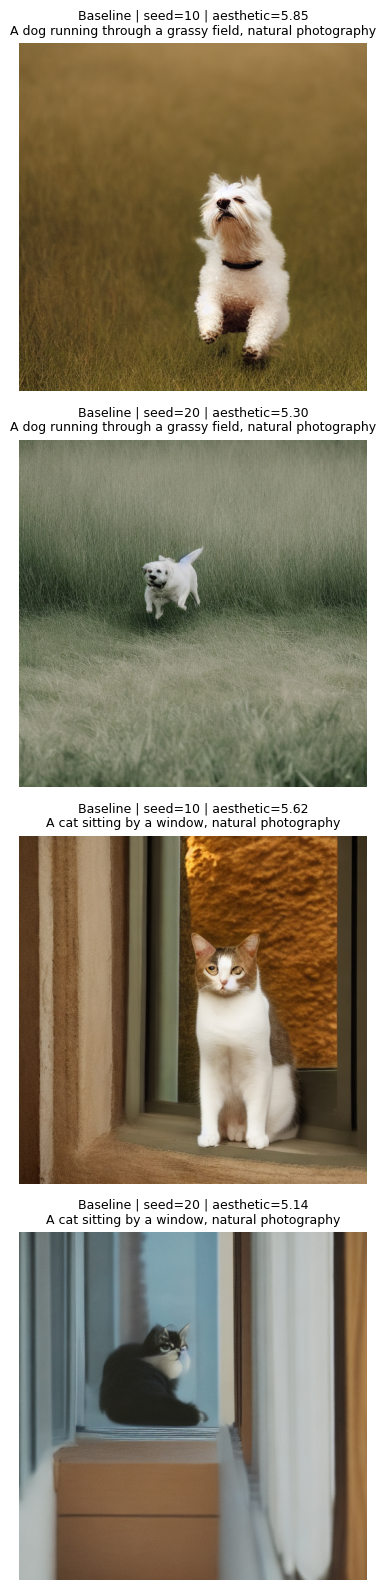

,method,prompt,prompt_index,seed,image_path,aesthetic_reward,generation_seconds,peak_gpu_memory_mb,num_inference_steps,guidance_scale
0,baseline,"A dog running through a grassy field, natural ...",0,10,/kaggle/working/svdd_evaluation/images/baselin...,5.850910,2.554817,6531.219727,8,7.5
1,baseline,"A dog running through a grassy field, natural ...",0,20,/kaggle/working/svdd_evaluation/images/baselin...,5.303805,1.549715,6531.219727,8,7.5
2,baseline,"A cat sitting by a window, natural photography",1,10,/kaggle/working/svdd_evaluation/images/baselin...,5.623748,1.586410,6531.219727,8,7.5
3,baseline,"A cat sitting by a window, natural photography",1,20,/kaggle/working/svdd_evaluation/images/baselin...,5.136990,1.578404,6531.219727,8,7.5


In [9]:
# Display generated images with prompt, seed, and reward.
n = len(preview_images)
fig, axes = plt.subplots(n, 1, figsize=(6, max(4, 4*n)))
if n == 1:
    axes = [axes]
for ax, (prompt, seed, image, score) in zip(axes, preview_images):
    ax.imshow(image)
    ax.set_title(f"Baseline | seed={seed} | aesthetic={score:.2f}\n{prompt}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

results_df = pd.DataFrame(records)
display(results_df)

The aesthetic score is a reward model output; it is not an objective guarantee of human-perceived quality. With only a few smoke-test samples, the summary is descriptive and does not establish a reliable improvement.

In [10]:
summary = results_df.groupby("method")["aesthetic_reward"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    min="min",
    max="max",
).reset_index()
summary.to_csv(OUTPUT_DIR / "summary_results.csv", index=False)
display(summary)
print("Per-image CSV:", OUTPUT_DIR / "per_image_results.csv")
print("Summary CSV:", OUTPUT_DIR / "summary_results.csv")
print("Images:", IMAGE_DIR)

,method,count,mean,median,std,min,max
0,baseline,4,5.478863,5.463777,0.319861,5.13699,5.85091


Per-image CSV: /kaggle/working/svdd_evaluation/per_image_results.csv
Summary CSV: /kaggle/working/svdd_evaluation/summary_results.csv
Images: /kaggle/working/svdd_evaluation/images


In [ ]:
PROMPTS = [
    "A red fox standing in a snowy forest, cinematic photography, natural lighting",
    "A beautiful Japanese street at night, glowing lanterns, wet pavement, cinematic photography"
]

In [65]:
%cd /kaggle/working/SVDD-image

!python -u inference_decoding_nonp.py \
    --device cuda:1 \
    --reward aesthetic \
    --bs 1 \
    --num_images 2 \
    --duplicate_size 2 \
    --variant MC \
    --seed 42

/kaggle/working/SVDD-image
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
Generating Images:   0%|                                  | 0/2 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion/pipeline_stable_diffusion.py:313: FutureWarning: `_encode_prompt()` is deprecated and it will be removed in a future version. Use `encode_prompt()` instead. Also, be aware that the output format changed from a concatenated tensor to a tuple.
  deprecate("_encode_prompt()", "1.0.0", deprecation_message, standard_warn=False)

100%|███████████████████████████████████████████| 50/50 [02:07<00:00,  2.55s/it]
/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion/pipeline_stable_diffusion.py:599: FutureWarning: The decode_latents me

In [66]:
!python -u inference_decoding_nonp.py \
    --device cuda:1 \
    --reward aesthetic \
    --bs 1 \
    --num_images 2 \
    --duplicate_size 2 \
    --variant PM \
    --seed 42

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
Generating Images:   0%|                                  | 0/2 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion/pipeline_stable_diffusion.py:313: FutureWarning: `_encode_prompt()` is deprecated and it will be removed in a future version. Use `encode_prompt()` instead. Also, be aware that the output format changed from a concatenated tensor to a tuple.
  deprecate("_encode_prompt()", "1.0.0", deprecation_message, standard_warn=False)

100%|███████████████████████████████████████████| 50/50 [02:15<00:00,  2.71s/it]
/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion/pipeline_stable_diffusion.py:599: FutureWarning: The decode_latents method is deprecated and will

In [67]:
%cd /kaggle/working/SVDD-image

import gc
import torch
from pathlib import Path
from datetime import datetime
from diffusers import StableDiffusionPipeline

prompts = [
    "A red fox standing in a snowy forest, cinematic photography, natural lighting",
    "A traditional Japanese street at night, glowing lanterns, wet pavement, cinematic photography",
]

# SVDD-style output structure
run_name = f"Baseline_M=2__{datetime.now().strftime('%Y.%m.%d_%H.%M.%S')}"
out_dir = Path("logs") / run_name / "eval_vis"
out_dir.mkdir(parents=True, exist_ok=False)

print("Baseline output directory:", out_dir.resolve())

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
    safety_checker=None,
).to("cuda:1")

pipe.set_progress_bar_config(disable=False)

for i, prompt in enumerate(prompts):
    generator = torch.Generator(device="cuda:1").manual_seed(42 + i)

    with torch.inference_mode():
        result = pipe(
            prompt=prompt,
            num_inference_steps=50,
            guidance_scale=7.5,
            generator=generator,
        )

    filename = out_dir / f"{i:03d}_baseline.png"
    result.images[0].save(filename)
    print(f"Saved: {filename}")

del pipe
gc.collect()
torch.cuda.empty_cache()

print("Baseline generation complete.")

/kaggle/working/SVDD-image
Baseline output directory: /kaggle/working/SVDD-image/logs/Baseline_M=2__2026.10.26_11.40.31/eval_vis


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

...

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/50 [00:00<?, ?it/s]

Saved: logs/Baseline_M=2__2026.10.26_11.40.31/eval_vis/000_baseline.png


  0%|          | 0/50 [00:00<?, ?it/s]

Saved: logs/Baseline_M=2__2026.10.26_11.40.31/eval_vis/001_baseline.png
Baseline generation complete.


/kaggle/working/SVDD-image
Baseline: /kaggle/working/SVDD-image/logs/Baseline_M=2__2026.10.26_11.40.31
SVDD-MC: /kaggle/working/SVDD-image/logs/MC_M=2__2026.10.26_11.26.51
SVDD-PM: /kaggle/working/SVDD-image/logs/PM_M=2__2026.10.26_11.31.53

Baseline images:
  0: 000_baseline.png
  1: 001_baseline.png

SVDD-MC images:
  0: 000_A red fox standing in a snowy forest, cinematic photography, natural lighting_score=6.440636.png
  1: 001_A traditional Japanese street at night, glowing lanterns, wet pavement, cinematic photography_score=6.064854.png

SVDD-PM images:
  0: 000_A red fox standing in a snowy forest, cinematic photography, natural lighting_score=6.371825.png
  1: 001_A traditional Japanese street at night, glowing lanterns, wet pavement, cinematic photography_score=6.137423.png

Aesthetic scorer classes/functions:
  AestheticScorerDiff(dtype)
  AestheticScorerDiff_Time(dtype)
  CLIPModel(config: transformers.models.clip.configuration_clip.CLIPConfig)
  CLIPProcessor(image_processor

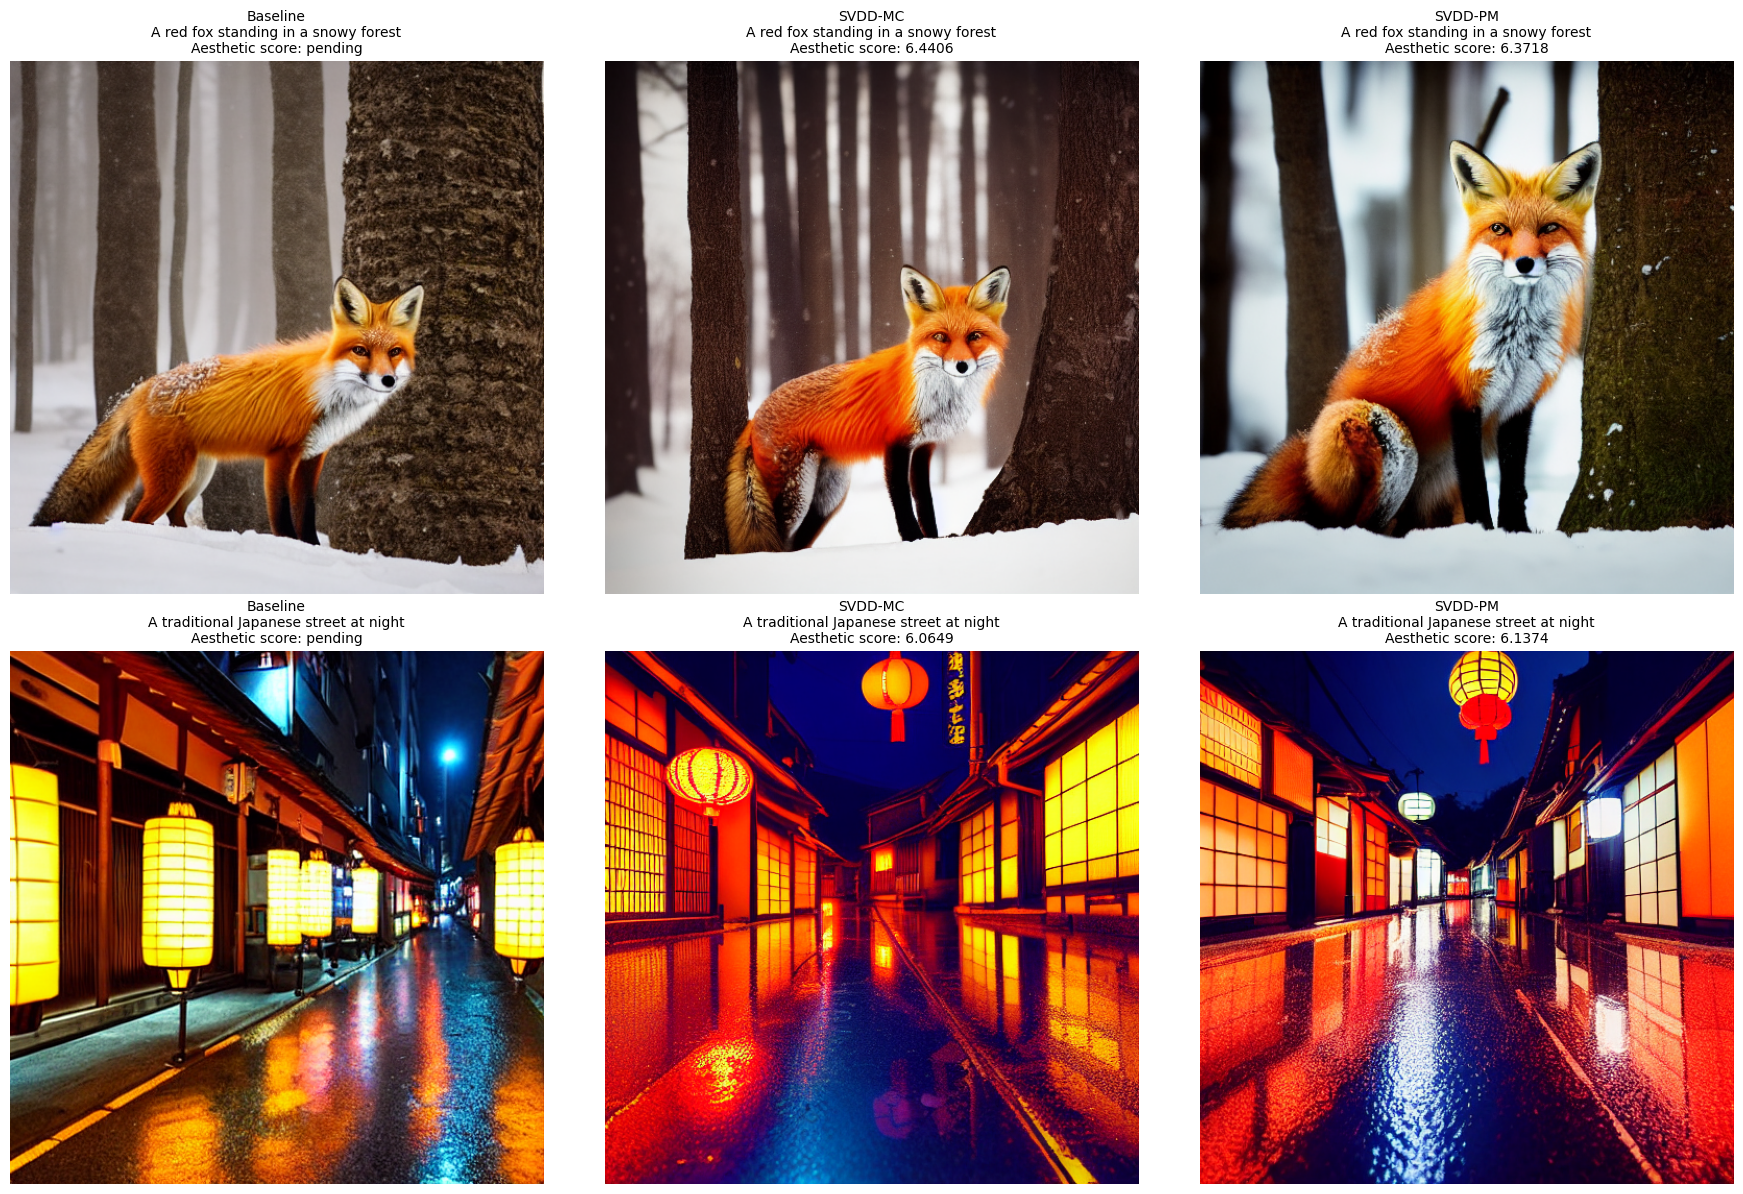

Figure saved: /kaggle/working/SVDD-image/logs/visual_comparison_metrics.png


,Prompt,Method,Aesthetic score,Difference vs baseline,Image path
0,A red fox standing in a snowy forest,Baseline,NaN,NaN,/kaggle/working/SVDD-image/logs/Baseline_M=2__...
1,A red fox standing in a snowy forest,SVDD-MC,6.440636,NaN,/kaggle/working/SVDD-image/logs/MC_M=2__2026.1...
2,A red fox standing in a snowy forest,SVDD-PM,6.371825,NaN,/kaggle/working/SVDD-image/logs/PM_M=2__2026.1...
3,A traditional Japanese street at night,Baseline,NaN,NaN,/kaggle/working/SVDD-image/logs/Baseline_M=2__...
4,A traditional Japanese street at night,SVDD-MC,6.064854,NaN,/kaggle/working/SVDD-image/logs/MC_M=2__2026.1...
5,A traditional Japanese street at night,SVDD-PM,6.137423,NaN,/kaggle/working/SVDD-image/logs/PM_M=2__2026.1...


Metrics CSV saved: /kaggle/working/SVDD-image/logs/comparison_metrics.csv


In [70]:
%cd /kaggle/working/SVDD-image

import gc
import re
import inspect
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# --------------------------------------------------
# 1. Locate the three runs
# --------------------------------------------------
ROOT = Path("/kaggle/working/SVDD-image")
LOGS = ROOT / "logs"

def latest_run(prefix):
    runs = sorted(
        LOGS.glob(f"{prefix}_M=*"),
        key=lambda p: p.stat().st_mtime
    )
    if not runs:
        raise FileNotFoundError(
            f"No {prefix} run found in {LOGS}. "
            "Check the run directory name."
        )
    return runs[-1]

runs = {
    "Baseline": latest_run("Baseline"),
    "SVDD-MC": latest_run("MC"),
    "SVDD-PM": latest_run("PM"),
}

for method, run in runs.items():
    print(f"{method}: {run}")

# --------------------------------------------------
# 2. Find the two images for each method
# --------------------------------------------------
prompts = {
    0: "A red fox standing in a snowy forest",
    1: "A traditional Japanese street at night",
}

def get_images(run):
    folder = run / "eval_vis"
    found = {}

    for p in folder.glob("*.png"):
        match = re.match(r"(\d+)_", p.name)
        if match:
            found[int(match.group(1))] = p

    return found

images = {name: get_images(run) for name, run in runs.items()}

for method, mapping in images.items():
    print(f"\n{method} images:")
    for idx, path in sorted(mapping.items()):
        print(f"  {idx}: {path.name}")

for method, mapping in images.items():
    if not {0, 1}.issubset(mapping):
        raise RuntimeError(
            f"{method} must contain images 000 and 001. "
            "Check the paths printed above."
        )

# --------------------------------------------------
# 3. Discover the repository's actual aesthetic scorer
# --------------------------------------------------
scorer_path = ROOT / "aesthetic_scorer.py"

if not scorer_path.exists():
    raise FileNotFoundError(f"Missing scorer: {scorer_path}")

scorer_module = importlib.import_module("aesthetic_scorer")

print("\nAesthetic scorer classes/functions:")
for name, obj in inspect.getmembers(scorer_module):
    if (inspect.isclass(obj) or inspect.isfunction(obj)) and not name.startswith("_"):
        try:
            signature = inspect.signature(obj)
        except (TypeError, ValueError):
            signature = "(signature unavailable)"
        print(f"  {name}{signature}")

print(
    "\nThe scorer API above must be used to calculate baseline scores. "
    "Do not treat missing scores as zero or compare different evaluators."
)

# --------------------------------------------------
# 4. Load any existing saved SVDD scores
# --------------------------------------------------
def existing_scores(run, image_mapping):
    # Check both the run root and eval_vis directory.
    candidates = [
        run / "scores.npy",
        run / "eval_vis" / "scores.npy",
    ]

    for candidate in candidates:
        if candidate.exists():
            values = np.asarray(
                np.load(candidate, allow_pickle=False)
            ).reshape(-1)
            if len(values) >= 2:
                return {i: float(values[i]) for i in range(2)}

    # SVDD output filenames often embed the aesthetic score.
    result = {}
    for idx, path in image_mapping.items():
        match = re.search(r"_score=([-+]?\d*\.?\d+)", path.name)
        if match:
            result[idx] = float(match.group(1))

    return result

scores = {
    method: existing_scores(runs[method], images[method])
    for method in runs
}

print("\nExisting saved scores:")
for method, values in scores.items():
    print(method, values if values else "(no saved scores found)")

# --------------------------------------------------
# 5. Visual comparison
# --------------------------------------------------
method_names = ["Baseline", "SVDD-MC", "SVDD-PM"]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for col, method in enumerate(method_names):
    for idx in range(2):
        path = images[method][idx]

        with Image.open(path) as im:
            axes[idx, col].imshow(im.convert("RGB"))

        score = scores[method].get(idx)
        score_label = (
            f"Aesthetic score: {score:.4f}"
            if score is not None
            else "Aesthetic score: pending"
        )

        axes[idx, col].set_title(
            f"{method}\n{prompts[idx]}\n{score_label}",
            fontsize=10
        )
        axes[idx, col].axis("off")

plt.tight_layout()

figure_path = LOGS / "visual_comparison_metrics.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

# --------------------------------------------------
# 6. Metrics table and differences where available
# --------------------------------------------------
records = []

for idx, prompt in prompts.items():
    baseline_score = scores["Baseline"].get(idx)

    for method in method_names:
        score = scores[method].get(idx)

        records.append({
            "Prompt": prompt,
            "Method": method,
            "Aesthetic score": score,
            "Difference vs baseline": (
                score - baseline_score
                if score is not None and baseline_score is not None
                else np.nan
            ),
            "Image path": str(images[method][idx]),
        })

df = pd.DataFrame(records)
display(df)

csv_path = LOGS / "comparison_metrics.csv"
df.to_csv(csv_path, index=False)

print("Metrics CSV saved:", csv_path)